# Exploratory Data Analysis (EDA)

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
chronic_kidney_disease = fetch_ucirepo(id=336) 
  
# data (as pandas dataframes) 
X = chronic_kidney_disease.data.features 
y = chronic_kidney_disease.data.targets 


In [20]:
df = pd.concat([X, y], axis=1)

print(df.shape)
df.head(5)

(400, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


In [21]:
print(chronic_kidney_disease.variables[['name', 'type', 'description']]) 

     name         type              description
0     age      Integer                      NaN
1      bp      Integer           blood pressure
2      sg  Categorical         specific gravity
3      al  Categorical                  albumin
4      su  Categorical                    sugar
5     rbc       Binary          red blood cells
6      pc       Binary                 pus cell
7     pcc       Binary          pus cell clumps
8      ba       Binary                 bacteria
9     bgr      Integer     blood glucose random
10     bu      Integer               blood urea
11     sc   Continuous         serum creatinine
12    sod      Integer                   sodium
13    pot   Continuous                potassium
14   hemo   Continuous               hemoglobin
15    pcv      Integer       packed cell volume
16   wbcc      Integer   white blood cell count
17   rbcc   Continuous     red blood cell count
18    htn       Binary             hypertension
19     dm       Binary        diabetes m

In [22]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    str    
 6   pc      335 non-null    str    
 7   pcc     396 non-null    str    
 8   ba      396 non-null    str    
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    str    
 19  dm      398 non-null    str    
 20  cad     398 non-null    str    
 21  appet   399 non-null    str    
 22  pe      399 n

In [23]:
print(df.dtypes)

age      float64
bp       float64
sg       float64
al       float64
su       float64
rbc          str
pc           str
pcc          str
ba           str
bgr      float64
bu       float64
sc       float64
sod      float64
pot      float64
hemo     float64
pcv      float64
wbcc     float64
rbcc     float64
htn          str
dm           str
cad          str
appet        str
pe           str
ane          str
class        str
dtype: object


In [24]:
# selects all str columns and make a list
str_cols = df.select_dtypes(exclude='number').columns.tolist()

# clean up the str columns
for c in str_cols:
    df[c] = df[c].str.strip().replace({'?': np.nan, '': np.nan})

# print unique values
for c in str_cols:
    print(c, df[c].unique())

rbc <ArrowStringArray>
[nan, 'normal', 'abnormal']
Length: 3, dtype: str
pc <ArrowStringArray>
['normal', 'abnormal', nan]
Length: 3, dtype: str
pcc <ArrowStringArray>
['notpresent', 'present', nan]
Length: 3, dtype: str
ba <ArrowStringArray>
['notpresent', 'present', nan]
Length: 3, dtype: str
htn <ArrowStringArray>
['yes', 'no', nan]
Length: 3, dtype: str
dm <ArrowStringArray>
['yes', 'no', nan]
Length: 3, dtype: str
cad <ArrowStringArray>
['no', 'yes', nan]
Length: 3, dtype: str
appet <ArrowStringArray>
['good', 'poor', nan]
Length: 3, dtype: str
pe <ArrowStringArray>
['no', 'yes', nan]
Length: 3, dtype: str
ane <ArrowStringArray>
['no', 'yes', nan]
Length: 3, dtype: str
class <ArrowStringArray>
['ckd', 'notckd']
Length: 2, dtype: str


In [25]:
ordinal_cols = ['sg', 'al', 'su']
num_cols = ['age', 'bp', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']
cat_cols = ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']

<Axes: title={'center': 'Fraction Missing'}>

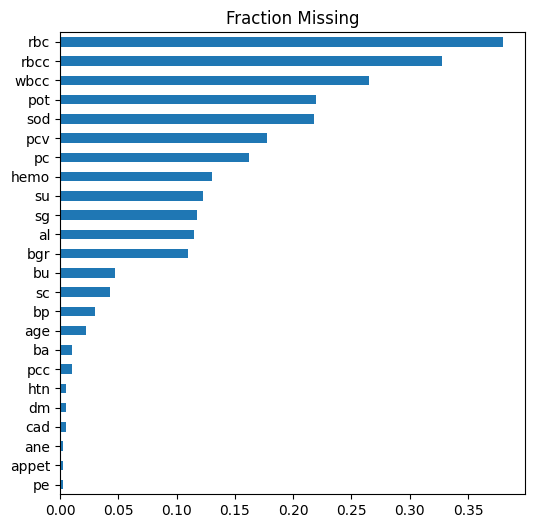

In [29]:
missing = df.isna().mean().sort_values()
missing[missing > 0].plot.barh(figsize=(6,6), title='Fraction Missing')

- Columns with the most missing data: `rbc` (~38%), `rbcc` (~33%), `wbcc` (~27%), `pot` and `sod` (~22%).
- Most other columns are missing less than 13%.
- The yes/no columns (`htn`, `dm`, `cad`, `appet`, `pe`, `ane`) are almost complete.
- **Takeaway:** No column is missing so much that it must be dropped, but several need a plan for filling in gaps.

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
ckd,250.0,3.632000,3.047248,0.0,1.0,3.0,5.0,11.0
notckd,150.0,0.693333,1.399648,0.0,0.0,0.0,0.0,6.0


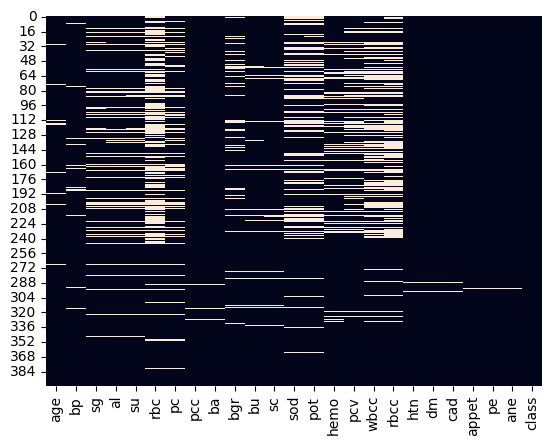

In [30]:
sns.heatmap(df.isna(), cbar=False)
df['n_missing'] = df.isna().sum(axis=1)
df.groupby('class')['n_missing'].describe()

- Missing values are **not random**. They are clustered in the top ~250 rows, which are the CKD patients.
- The bottom ~150 rows (not CKD) are almost complete.
- This means missing data is linked to the diagnosis. Healthy patients were tested more fully.
- **Takeaway:** A model could learn "test is missing → CKD" instead of real medical signals. Check `n_missing` by class, and consider comparing results with and without missing-value indicator columns.

<Axes: xlabel='class'>

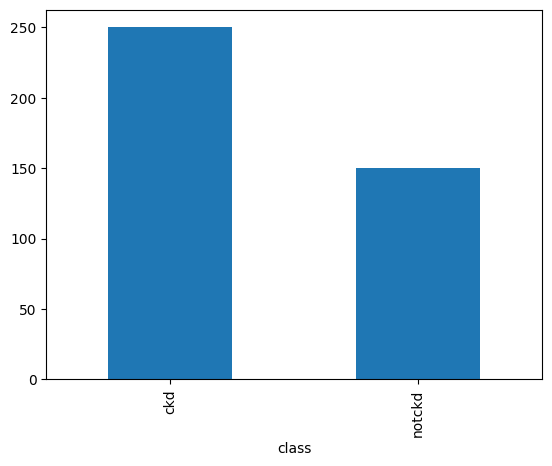

In [33]:
df['class'].value_counts().plot.bar()

- About 250 CKD vs 150 not CKD (≈ 62% / 38%).
- Mild imbalance, not severe.
- **Takeaway:** Use stratified train/test splits and look at precision and recall, not just accuracy.

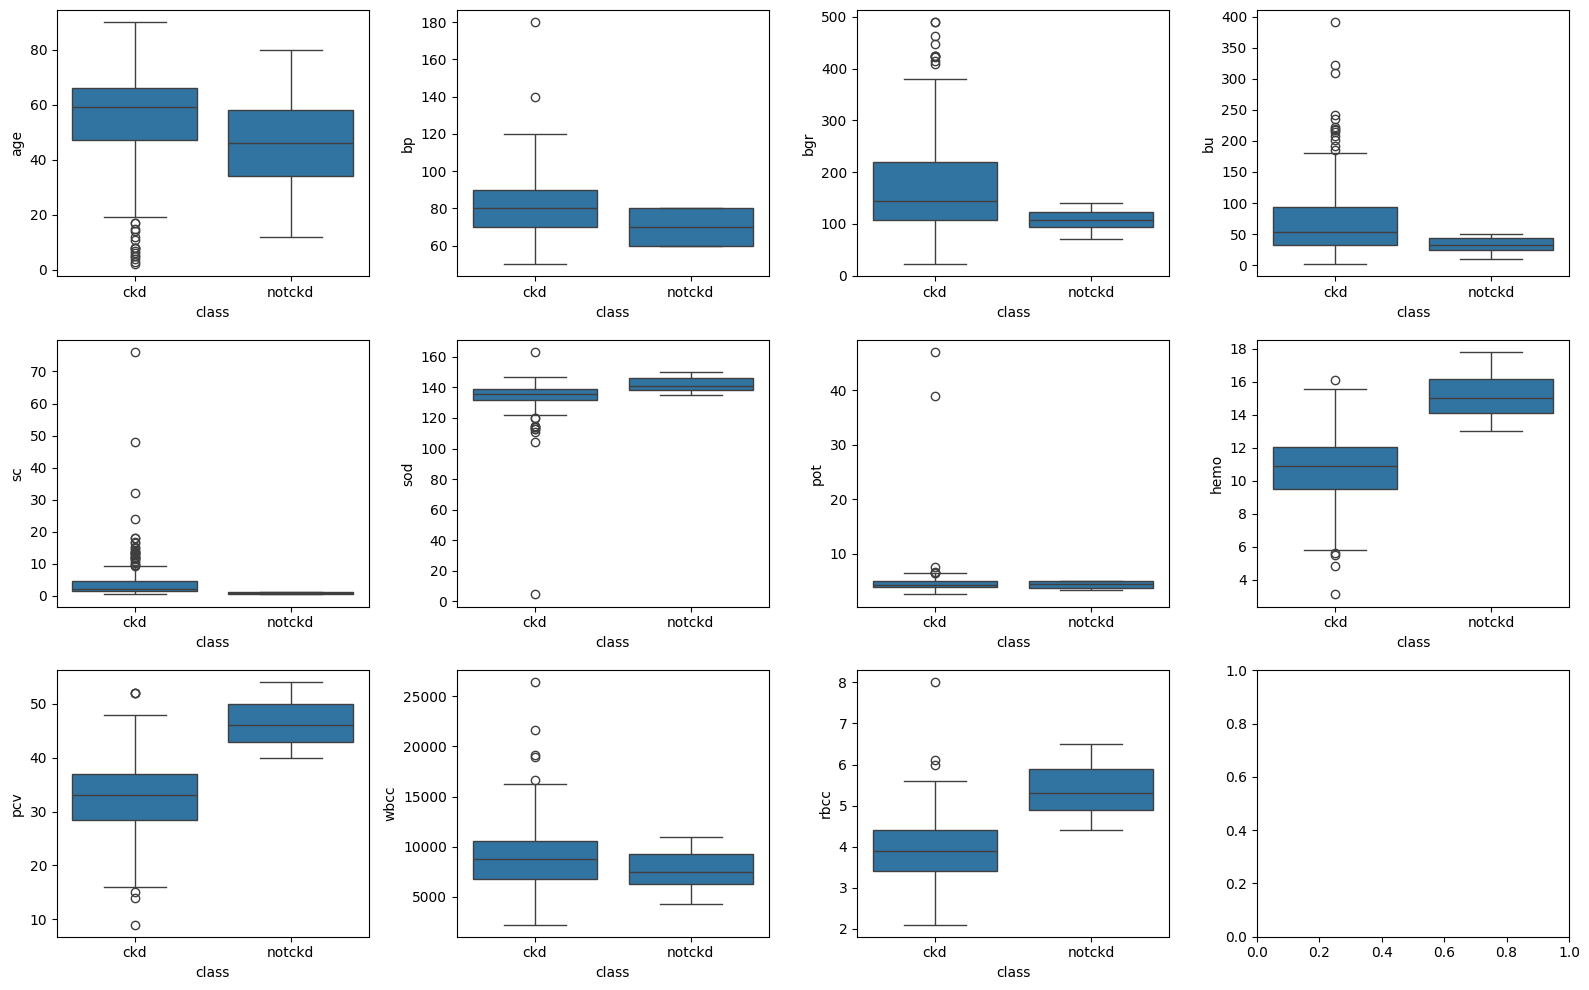

In [34]:
fig, axes = plt.subplots(3, 4, figsize=(16,10))

for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x='class', y=c, ax=ax)

plt.tight_layout()

**Clearly different between CKD and not CKD:**
- `hemo`, `pcv`, `rbcc` are **lower** in CKD (anemia is common in kidney disease).
- `sc` (creatinine), `bu` (urea) are **higher** in CKD. These are core kidney markers.
- `bgr` (blood glucose) is **higher** in CKD.

**Somewhat different:**
- `age` is older in CKD, `bp` is a bit higher, and `sod` is a bit lower.

**Barely different:**
- `wbcc` and `pot` overlap a lot between the classes.

**Data problems to check:**
- `pot` has values near 39 and 47 (normal is ~3.5-5), and `sod` has a value near 5 (normal is ~135-145). These are likely typos.
- A few extreme values in `sc` and `bp` may be real but should be checked.
- Many skewed features (`sc`, `bu`, `bgr`, `wbcc`) would be easier to read on a log scale.
- The last subplot is empty because 11 features don't fill a 3×4 grid.

In [37]:
for c in cat_cols + ordinal_cols:
    print(pd.crosstab(df[c], df['class'], normalize='index').round(2), '\n')

class     ckd  notckd
rbc                  
abnormal  1.0     0.0
normal    0.3     0.7 

class      ckd  notckd
pc                    
abnormal  1.00    0.00
normal    0.46    0.54 

class        ckd  notckd
pcc                     
notpresent  0.59    0.41
present     1.00    0.00 

class        ckd  notckd
ba                      
notpresent  0.61    0.39
present     1.00    0.00 

class   ckd  notckd
htn                
no     0.41    0.59
yes    1.00    0.00 

class   ckd  notckd
dm                 
no     0.43    0.57
yes    1.00    0.00 

class   ckd  notckd
cad                
no     0.59    0.41
yes    1.00    0.00 

class   ckd  notckd
appet              
good   0.53    0.47
poor   1.00    0.00 

class   ckd  notckd
pe                 
no     0.54    0.46
yes    1.00    0.00 

class   ckd  notckd
ane                
no     0.56    0.44
yes    1.00    0.00 

class   ckd  notckd
sg                 
1.005  1.00    0.00
1.010  1.00    0.00
1.015  1.00    0.00
1.020  0.29    0.71


- `rbc` abnormal, `pc` abnormal, `pcc` present, `ba` present, and `htn` yes are **100% CKD**.
- The "normal/absent/no" values are mixed between the two classes, so only the positive finding is decisive.
- For `al` (albumin), the higher levels (3, 4, 5) are 100% CKD.

<Axes: >

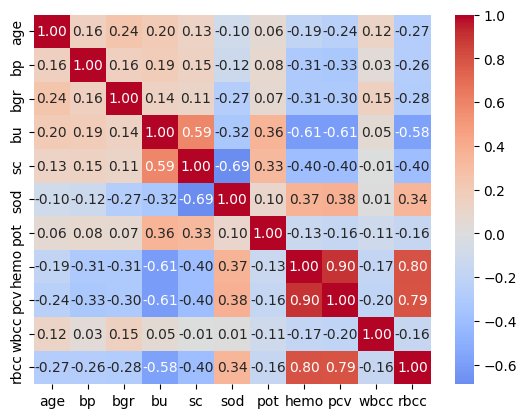

In [38]:
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)

- `hemo`, `pcv`, `rbcc` are **highly correlated** (0.79 to 0.90). They carry almost the same information.
  - This can cause problems for linear/logistic models. Keep one, combine them, or use regularization.
  - Tree-based models are fine with it.
- `bu` and `sc` are moderately correlated (0.59), as expected for two kidney markers.
- `sc` and `sod` are negatively correlated (-0.69), but this may be inflated by the `sod` typo. Recheck after cleaning.
- Everything else is weakly correlated (mostly |r| < 0.3).

## Next Steps: Feature Engineering & Pipeline

**Note:** fixed cleaning rules can happen before the split. Anything that *learns* from the data (imputing, scaling) goes inside the pipeline to avoid data leakage.

---

### 1. Clean (before splitting)
- Set likely data-entry errors to `NaN`: `sod` < 100 and `pot` > 10.
- Encode the target: `ckd = 1`, `notckd = 0`.
- Drop `n_missing` from the features. It is a direct proxy for the class and would inflate scores.

### 2. Split first (stratified)
- 80/20 train/test split with `stratify=y` and a fixed `random_state`.
- Don't touch the test set until the very end.

### 3. Feature engineering plan

| Idea | Why |
|---|---|
| Log-transform `sc`, `bu`, `bgr`, `wbcc` | These are right-skewed. |
| Add missing-value indicators | Missingness is linked to the class, so **test with and without**. |
| Keep `sg`, `al`, `su` as numeric | They are ordinal, so the order carries information. |
| One-hot encode categoricals | Use `drop='if_binary'` for the yes/no columns. |
| Handle `hemo`, `pcv`, `rbcc` | They are highly correlated (0.79 to 0.90). Keep one or use regularization for linear models. Trees are fine. |
| Optional: `bu / sc` ratio | Keep it only if it improves CV scores. |

### 4. Pipeline structure
- **Skewed numeric** (`sc`, `bu`, `bgr`, `wbcc`): median impute → log → scale
- **Other numeric**: median impute → scale
- **Ordinal** (`sg`, `al`, `su`): most-frequent impute → scale
- **Categorical**: most-frequent impute → one-hot encode
- Wrap everything in a `ColumnTransformer`, then add the model as the last step of a `Pipeline`.

### 5. Model comparison (cross-validation only)
- Models: Logistic Regression and Random Forest, both with `class_weight='balanced'`.
- Use 5-fold `StratifiedKFold`.
- Metrics: ROC-AUC, recall, precision, F1. Don't rely on accuracy alone.
- Run each model **with and without** missing indicators.
  - Scores about the same → the model is using real medical signals.
  - Scores drop without the flags → the model leans on missingness.

### 6. Robustness checks
- Drop the most-missing columns (`rbc`, `rbcc`, `wbcc`) and see if performance holds.
- Check feature importance. The top features should be things like `hemo`, `sc`, `al`, `sg`, not missing-indicator columns.
- Try a smaller feature set (5 to 6 features). With this much separation it may do just as well and be easier to explain.

### 7. Final evaluation (once)
- Choose the final model using CV results only.
- Fit on the full training set and score on the test set one time.
- With only ~80 test rows, a few errors can swing the metrics, so report the CV scores alongside the test score.

### Watch-outs
- Class-dependent missing data is the biggest risk. It could make results look better than they would be on real patients.
- High accuracy is expected here, so a good score alone doesn't prove the model is reliable.
- Small dataset (400 rows): prefer cross-validation over a single split.